# Homework 2. Customer Churn Prediction
## Environment setup

In [1]:
!pip install -q pgserver sqlalchemy psycopg2-binary pandas

import pgserver
import pandas as pd
from sqlalchemy import create_engine, text

# Start PostgreSQL 16
pg = pgserver.get_server('/tmp/pg_data')
engine = create_engine(pg.get_uri())

# Check the database connection and PostgreSQL version
with engine.connect() as conn:
    version = conn.execute(text("SELECT version()")).scalar()
    print(version)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.3/11.3 MB 53.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.3/4.3 MB 40.8 MB/s eta 0:00:00
PostgreSQL 16.2 on x86_64-pc-linux-gnu, compiled by gcc (GCC) 10.2.1 20210130 (Red Hat 10.2.1-11), 64-bit


In [2]:
# Check database information
df = pd.read_sql("""
    SELECT
        current_database() AS db,
        current_user AS usr,
        version() AS pg_version
""", engine)

display(df)

,db,usr,pg_version
0,postgres,postgres,"PostgreSQL 16.2 on x86_64-pc-linux-gnu, compil..."


## 1. ER-діаграма

**Обраний сценарій:** Customer Churn Prediction.

Мета проєкту - створити базу даних для прогнозування відтоку
клієнтів (churn). Модель повинна визначати, чи припинить клієнт
користуватися послугами протягом наступних 30 днів.

Для цього створено три основні бізнесові сутності:
- Customers - інформація про клієнтів.
- Service Plans - доступні тарифні плани.
- Subscriptions - підписки клієнтів на тарифні плани.

Також передбачено offline feature store для зберігання історії
ознак, online feature store для швидких прогнозів та таблицю
training events для навчання моделі.

Зв'язок між клієнтами й тарифними планами є M:N і реалізований
через таблицю subscriptions.

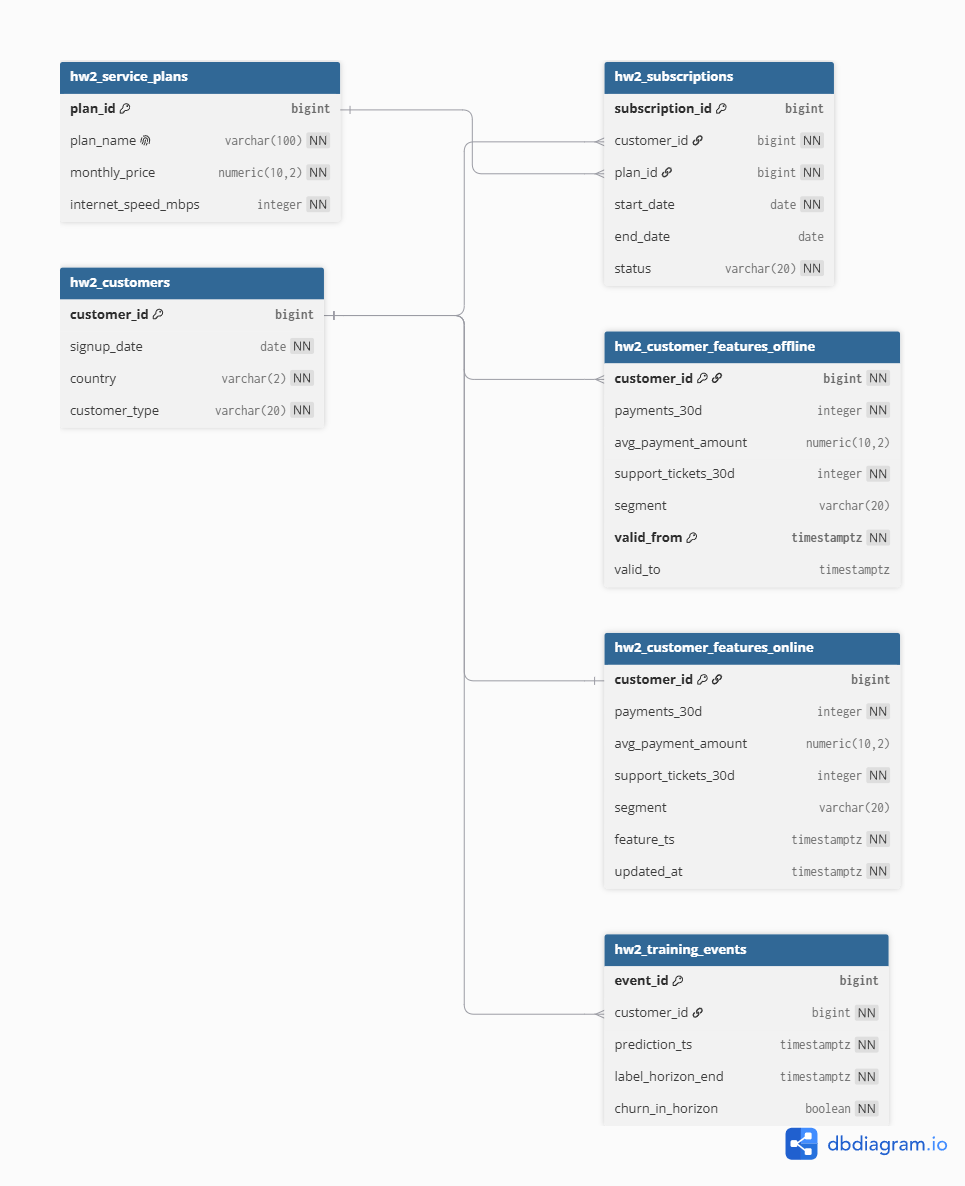


## 2. PostgreSQL DDL

In [3]:
# Create the database schema
ddl = """
SET TIME ZONE 'UTC';

DROP TABLE IF EXISTS
    hw2_customer_features_online,
    hw2_training_events,
    hw2_customer_features_offline,
    hw2_subscriptions,
    hw2_service_plans,
    hw2_customers
CASCADE;

CREATE TABLE hw2_customers (
    customer_id BIGINT PRIMARY KEY,
    signup_date DATE NOT NULL,
    country VARCHAR(2) NOT NULL,
    customer_type VARCHAR(20) NOT NULL
        CHECK (customer_type IN ('Personal', 'Business'))
);

CREATE TABLE hw2_service_plans (
    plan_id BIGINT PRIMARY KEY,
    plan_name VARCHAR(100) NOT NULL UNIQUE,
    monthly_price NUMERIC(10, 2) NOT NULL
        CHECK (monthly_price >= 0),
    internet_speed_mbps INTEGER NOT NULL
        CHECK (internet_speed_mbps > 0)
);

CREATE TABLE hw2_subscriptions (
    subscription_id BIGINT PRIMARY KEY,
    customer_id BIGINT NOT NULL
        REFERENCES hw2_customers(customer_id),
    plan_id BIGINT NOT NULL
        REFERENCES hw2_service_plans(plan_id),
    start_date DATE NOT NULL,
    end_date DATE,
    status VARCHAR(20) NOT NULL
        CHECK (status IN ('Active', 'Cancelled', 'Expired')),
    CHECK (end_date IS NULL OR end_date >= start_date)
);

CREATE TABLE hw2_customer_features_offline (
    customer_id BIGINT NOT NULL
        REFERENCES hw2_customers(customer_id),
    payments_30d INTEGER NOT NULL
        CHECK (payments_30d >= 0),
    avg_payment_amount NUMERIC(10, 2)
        CHECK (
            avg_payment_amount IS NULL
            OR avg_payment_amount >= 0
        ),
    support_tickets_30d INTEGER NOT NULL
        CHECK (support_tickets_30d >= 0),
    segment VARCHAR(20),
    valid_from TIMESTAMPTZ NOT NULL,
    valid_to TIMESTAMPTZ,

    PRIMARY KEY (customer_id, valid_from),

    CHECK (valid_to IS NULL OR valid_to > valid_from)
);

CREATE INDEX hw2_idx_features_asof
    ON hw2_customer_features_offline
    (customer_id, valid_from DESC);

CREATE TABLE hw2_training_events (
    event_id BIGINT GENERATED BY DEFAULT AS IDENTITY PRIMARY KEY,
    customer_id BIGINT NOT NULL
        REFERENCES hw2_customers(customer_id),
    prediction_ts TIMESTAMPTZ NOT NULL,
    label_horizon_end TIMESTAMPTZ NOT NULL,
    churn_in_horizon BOOLEAN NOT NULL,

    CHECK (label_horizon_end > prediction_ts)
);

CREATE TABLE hw2_customer_features_online (
    customer_id BIGINT PRIMARY KEY
        REFERENCES hw2_customers(customer_id),
    payments_30d INTEGER NOT NULL
        CHECK (payments_30d >= 0),
    avg_payment_amount NUMERIC(10, 2)
        CHECK (
            avg_payment_amount IS NULL
            OR avg_payment_amount >= 0
        ),
    support_tickets_30d INTEGER NOT NULL
        CHECK (support_tickets_30d >= 0),
    segment VARCHAR(20),
    feature_ts TIMESTAMPTZ NOT NULL,
    updated_at TIMESTAMPTZ NOT NULL
        DEFAULT CURRENT_TIMESTAMP
);
"""

# Execute all DDL statements in one transaction
with engine.begin() as conn:
    conn.execute(text(ddl))

print("Database schema created successfully.")

Database schema created successfully.


In [4]:
# Verify that all homework tables exist
df = pd.read_sql(text("""
    SELECT table_name
    FROM information_schema.tables
    WHERE table_schema = 'public'
      AND table_name LIKE 'hw2_%'
    ORDER BY table_name
"""), engine)

display(df)

,table_name
0,hw2_customer_features_offline
1,hw2_customer_features_online
2,hw2_customers
3,hw2_service_plans
4,hw2_subscriptions
5,hw2_training_events


## 3. Нормалізація та денормалізація

При створенні бази даних я намагалася розділити інформацію між таблицями так, щоб не дублювати одні й ті самі дані.

Таблиці `hw2_customers`, `hw2_service_plans` і `hw2_subscriptions` відповідають третій нормальній формі (3НФ). Наприклад, інформація про тарифні плани зберігається окремо, а в таблиці підписок є тільки `plan_id`. Завдяки цьому, якщо ціна тарифу зміниться, її не потрібно оновлювати в кожній підписці.

У цих таблицях дані залежать від їхніх первинних ключів. Наприклад, `customer_id` визначає інформацію про клієнта, `plan_id` - дані тарифу, а `subscription_id` - інформацію про підписку. В історичній таблиці ознаки залежать від пари `customer_id` і `valid_from`, оскільки для одного клієнта вони можуть змінюватися з часом.

Для online feature store я використала денормалізацію. У таблиці `hw2_customer_features_online` всі поточні ознаки клієнта зберігаються разом. Це дозволяє швидко отримати їх за `customer_id` без додаткових `JOIN`, що важливо для роботи ML-моделі.

Але через це частина даних повторюється в offline та online таблицях. Якщо оновити тільки одну з них, інформація може відрізнятися.

Щоб цього уникнути, online-таблицю потрібно оновлювати з offline-таблиці. Наприклад, за допомогою `UPSERT` можна додавати нові записи або оновлювати вже наявні, використовуючи останні актуальні значення ознак.

## 4. Point-in-Time Correctness

У цій частині роботи я перевірю, як правильно використовувати історичні дані для навчання ML-моделі.

Для прикладу створю тестові дані трьох клієнтів. Для кожного клієнта буде по 4 версії ознак за різні періоди часу.

Потім за допомогою SQL-запитів перевірю, чи можна отримати саме ті дані, які були актуальними на момент прогнозування (`prediction_ts`).

Це потрібно, щоб модель не використовувала інформацію з майбутнього, якої на момент прогнозу ще не було.

In [5]:
# Insert customers, service plans, and subscriptions
insert_business_data = """
INSERT INTO hw2_customers
    (customer_id, signup_date, country, customer_type)
VALUES
    (1, DATE '2024-01-10', 'UA', 'Personal'),
    (2, DATE '2024-02-20', 'PL', 'Personal'),
    (42, DATE '2024-03-15', 'UA', 'Business');

INSERT INTO hw2_service_plans
    (plan_id, plan_name, monthly_price, internet_speed_mbps)
VALUES
    (1, 'Basic', 20.00, 100),
    (2, 'Standard', 35.00, 300),
    (3, 'Premium', 50.00, 1000);

INSERT INTO hw2_subscriptions
    (subscription_id, customer_id, plan_id, start_date, end_date, status)
VALUES
    (1, 1, 1, DATE '2024-01-10', NULL, 'Active'),
    (2, 2, 2, DATE '2024-02-20', DATE '2025-02-20', 'Cancelled'),
    (3, 42, 3, DATE '2024-03-15', DATE '2025-02-18', 'Cancelled');
"""

with engine.begin() as conn:
    conn.execute(text(insert_business_data))

print("Business data inserted successfully.")

Business data inserted successfully.


In [6]:
# Insert 12 historical feature records for 3 customers
insert_features = """
INSERT INTO hw2_customer_features_offline
    (customer_id, payments_30d, avg_payment_amount,
     support_tickets_30d, segment, valid_from, valid_to)
VALUES
    -- Customer 1
    (1, 1, 20.00, 0, 'Low',
     TIMESTAMPTZ '2024-11-01 00:00:00+00',
     TIMESTAMPTZ '2024-12-15 00:00:00+00'),
    (1, 1, 20.00, 1, 'Low',
     TIMESTAMPTZ '2024-12-15 00:00:00+00',
     TIMESTAMPTZ '2025-01-01 00:00:00+00'),
    (1, 1, 20.00, 0, 'Low',
     TIMESTAMPTZ '2025-01-01 00:00:00+00',
     TIMESTAMPTZ '2025-02-01 00:00:00+00'),
    (1, 1, 20.00, 0, 'Low',
     TIMESTAMPTZ '2025-02-01 00:00:00+00',
     NULL),

    -- Customer 2
    (2, 1, 35.00, 0, 'Medium',
     TIMESTAMPTZ '2024-11-01 00:00:00+00',
     TIMESTAMPTZ '2024-12-15 00:00:00+00'),
    (2, 1, 35.00, 2, 'Medium',
     TIMESTAMPTZ '2024-12-15 00:00:00+00',
     TIMESTAMPTZ '2025-01-01 00:00:00+00'),
    (2, 0, NULL, 3, 'High',
     TIMESTAMPTZ '2025-01-01 00:00:00+00',
     TIMESTAMPTZ '2025-02-01 00:00:00+00'),
    (2, 0, NULL, 4, 'High',
     TIMESTAMPTZ '2025-02-01 00:00:00+00',
     NULL),

    -- Customer 42
    (42, 2, 50.00, 0, 'Low',
     TIMESTAMPTZ '2024-11-01 00:00:00+00',
     TIMESTAMPTZ '2024-12-15 00:00:00+00'),
    (42, 1, 50.00, 1, 'Medium',
     TIMESTAMPTZ '2024-12-15 00:00:00+00',
     TIMESTAMPTZ '2025-01-01 00:00:00+00'),
    (42, 1, 50.00, 3, 'High',
     TIMESTAMPTZ '2025-01-01 00:00:00+00',
     TIMESTAMPTZ '2025-02-01 00:00:00+00'),
    (42, 0, NULL, 4, 'High',
     TIMESTAMPTZ '2025-02-01 00:00:00+00',
     NULL);
"""

with engine.begin() as conn:
    conn.execute(text(insert_features))

print("Historical features inserted successfully.")

Historical features inserted successfully.


In [7]:
# Count historical versions for each customer
df = pd.read_sql(text("""
    SELECT
        customer_id,
        COUNT(*) AS version_count
    FROM hw2_customer_features_offline
    GROUP BY customer_id
    ORDER BY customer_id
"""), engine)

display(df)

,customer_id,version_count
0,1,4
1,2,4
2,42,4


In [8]:
# Insert historical prediction events and their labels
insert_training_events = """
INSERT INTO hw2_training_events
    (customer_id, prediction_ts, label_horizon_end, churn_in_horizon)
VALUES
    (1,
     TIMESTAMPTZ '2024-12-10 10:00:00+00',
     TIMESTAMPTZ '2025-01-09 10:00:00+00',
     FALSE),

    (1,
     TIMESTAMPTZ '2025-01-15 10:00:00+00',
     TIMESTAMPTZ '2025-02-14 10:00:00+00',
     FALSE),

    (2,
     TIMESTAMPTZ '2024-12-20 10:00:00+00',
     TIMESTAMPTZ '2025-01-19 10:00:00+00',
     FALSE),

    (2,
     TIMESTAMPTZ '2025-01-25 10:00:00+00',
     TIMESTAMPTZ '2025-02-24 10:00:00+00',
     TRUE),

    (42,
     TIMESTAMPTZ '2024-12-10 10:00:00+00',
     TIMESTAMPTZ '2025-01-09 10:00:00+00',
     FALSE),

    (42,
     TIMESTAMPTZ '2024-12-20 10:00:00+00',
     TIMESTAMPTZ '2025-01-19 10:00:00+00',
     FALSE),

    (42,
     TIMESTAMPTZ '2025-01-25 10:00:00+00',
     TIMESTAMPTZ '2025-02-24 10:00:00+00',
     TRUE);
"""

with engine.begin() as conn:
    conn.execute(text(insert_training_events))

print("Training events inserted successfully.")

Training events inserted successfully.


In [9]:
# Get customer 42 features as of December 10
df = pd.read_sql(text("""
    SELECT
        customer_id,
        payments_30d,
        avg_payment_amount,
        support_tickets_30d,
        segment,
        valid_from,
        valid_to
    FROM hw2_customer_features_offline
    WHERE customer_id = 42
      AND valid_from <= TIMESTAMPTZ '2024-12-10 10:00:00+00'
      AND (
          valid_to > TIMESTAMPTZ '2024-12-10 10:00:00+00'
          OR valid_to IS NULL
      )
"""), engine)

display(df)

,customer_id,payments_30d,avg_payment_amount,support_tickets_30d,segment,valid_from,valid_to
0,42,2,50.0,0,Low,2024-11-01 00:00:00+00:00,2024-12-15 00:00:00+00:00


In [10]:
# Get customer 42 features as of December 20
df = pd.read_sql(text("""
    SELECT
        customer_id,
        payments_30d,
        avg_payment_amount,
        support_tickets_30d,
        segment,
        valid_from,
        valid_to
    FROM hw2_customer_features_offline
    WHERE customer_id = 42
      AND valid_from <= TIMESTAMPTZ '2024-12-20 10:00:00+00'
      AND (
          valid_to > TIMESTAMPTZ '2024-12-20 10:00:00+00'
          OR valid_to IS NULL
      )
"""), engine)

display(df)

,customer_id,payments_30d,avg_payment_amount,support_tickets_30d,segment,valid_from,valid_to
0,42,1,50.0,1,Medium,2024-12-15 00:00:00+00:00,2025-01-01 00:00:00+00:00


In [11]:
# Create point-in-time correct training data
training_df = pd.read_sql(text("""
    SELECT
        e.event_id,
        e.customer_id,
        e.prediction_ts,
        e.label_horizon_end,
        e.churn_in_horizon,
        f.payments_30d,
        f.avg_payment_amount,
        f.support_tickets_30d,
        f.segment
    FROM hw2_training_events AS e
    LEFT JOIN hw2_customer_features_offline AS f
        ON f.customer_id = e.customer_id
       AND f.valid_from <= e.prediction_ts
       AND (
           f.valid_to > e.prediction_ts
           OR f.valid_to IS NULL
       )
    ORDER BY e.event_id
"""), engine)

display(training_df)

,event_id,customer_id,prediction_ts,label_horizon_end,churn_in_horizon,payments_30d,avg_payment_amount,support_tickets_30d,segment
0,1,1,2024-12-10 10:00:00+00:00,2025-01-09 10:00:00+00:00,False,1,20.0,0,Low
1,2,1,2025-01-15 10:00:00+00:00,2025-02-14 10:00:00+00:00,False,1,20.0,0,Low
2,3,2,2024-12-20 10:00:00+00:00,2025-01-19 10:00:00+00:00,False,1,35.0,2,Medium
3,4,2,2025-01-25 10:00:00+00:00,2025-02-24 10:00:00+00:00,True,0,NaN,3,High
4,5,42,2024-12-10 10:00:00+00:00,2025-01-09 10:00:00+00:00,False,2,50.0,0,Low
5,6,42,2024-12-20 10:00:00+00:00,2025-01-19 10:00:00+00:00,False,1,50.0,1,Medium
6,7,42,2025-01-25 10:00:00+00:00,2025-02-24 10:00:00+00:00,True,1,50.0,3,High


In [12]:
# Verify that every training event has exactly one feature row
assert len(training_df) == 7
assert training_df["event_id"].is_unique
assert training_df["segment"].notna().all()

print("Training data verification passed.")
print(f"Total training examples: {len(training_df)}")

Training data verification passed.
Total training examples: 7


In [13]:
# Check for overlapping historical feature intervals
overlaps_df = pd.read_sql(text("""
    SELECT
        a.customer_id,
        a.valid_from AS a_from,
        a.valid_to AS a_to,
        b.valid_from AS b_from,
        b.valid_to AS b_to
    FROM hw2_customer_features_offline AS a
    JOIN hw2_customer_features_offline AS b
        ON a.customer_id = b.customer_id
       AND a.valid_from <
           COALESCE(b.valid_to, 'infinity'::timestamptz)
       AND b.valid_from <
           COALESCE(a.valid_to, 'infinity'::timestamptz)
       AND a.valid_from < b.valid_from
    ORDER BY a.customer_id
"""), engine)

display(overlaps_df)

assert overlaps_df.empty, "Overlapping feature intervals found!"
print("No overlapping intervals found.")

,customer_id,a_from,a_to,b_from,b_to


No overlapping intervals found.


In [14]:
# Demonstrate duplicate records from a JOIN without time conditions
comparison_df = pd.read_sql(text("""
    SELECT
        'Incorrect JOIN' AS join_type,
        COUNT(*) AS row_count
    FROM hw2_training_events AS e
    JOIN hw2_customer_features_offline AS f
        ON e.customer_id = f.customer_id

    UNION ALL

    SELECT
        'AS-OF JOIN' AS join_type,
        COUNT(*) AS row_count
    FROM hw2_training_events AS e
    LEFT JOIN hw2_customer_features_offline AS f
        ON e.customer_id = f.customer_id
       AND f.valid_from <= e.prediction_ts
       AND (
           f.valid_to > e.prediction_ts
           OR f.valid_to IS NULL
       )
"""), engine)

display(comparison_df)

,join_type,row_count
0,Incorrect JOIN,28
1,AS-OF JOIN,7


In [15]:
# Update online features using the latest offline versions
upsert_online = """
INSERT INTO hw2_customer_features_online (
    customer_id,
    payments_30d,
    avg_payment_amount,
    support_tickets_30d,
    segment,
    feature_ts
)
SELECT DISTINCT ON (customer_id)
    customer_id,
    payments_30d,
    avg_payment_amount,
    support_tickets_30d,
    segment,
    valid_from
FROM hw2_customer_features_offline
WHERE valid_from <= CURRENT_TIMESTAMP
  AND (valid_to > CURRENT_TIMESTAMP OR valid_to IS NULL)
ORDER BY customer_id, valid_from DESC

ON CONFLICT (customer_id)
DO UPDATE SET
    payments_30d = EXCLUDED.payments_30d,
    avg_payment_amount = EXCLUDED.avg_payment_amount,
    support_tickets_30d = EXCLUDED.support_tickets_30d,
    segment = EXCLUDED.segment,
    feature_ts = EXCLUDED.feature_ts,
    updated_at = CURRENT_TIMESTAMP
WHERE hw2_customer_features_online.feature_ts <= EXCLUDED.feature_ts;
"""

with engine.begin() as conn:
    conn.execute(text(upsert_online))

print("Online feature store updated successfully.")

Online feature store updated successfully.


In [16]:
# View current online features
online_df = pd.read_sql(text("""
    SELECT
        customer_id,
        payments_30d,
        avg_payment_amount,
        support_tickets_30d,
        segment,
        feature_ts
    FROM hw2_customer_features_online
    ORDER BY customer_id
"""), engine)

display(online_df)

,customer_id,payments_30d,avg_payment_amount,support_tickets_30d,segment,feature_ts
0,1,1,20.0,0,Low,2025-02-01 00:00:00+00:00
1,2,0,NaN,4,High,2025-02-01 00:00:00+00:00
2,42,0,NaN,4,High,2025-02-01 00:00:00+00:00


### Пояснення результатів

Для отримання історичних ознак я використала AS-OF запити, які враховують час прогнозування.

Умова `valid_from <= prediction_ts` потрібна, щоб вибрати тільки ті версії ознак, які вже існували на момент прогнозу.

Умова `valid_to > prediction_ts OR valid_to IS NULL` перевіряє, що вибрана версія ще була актуальною. `NULL` означає, що це остання версія, для якої немає дати завершення.

Інтервали мають формат `[valid_from, valid_to)`. Це означає, що початок періоду включається, а кінець - ні. Завдяки цьому дві послідовні версії можуть мати однаковий час завершення та початку, але не перекриватися.

Для перевірки я виконала запити для клієнта 42 на дві різні дати. На 10 грудня він мав 2 платежі та 0 звернень до підтримки, а на 20 грудня - вже 1 платіж та 1 звернення.

Також я порівняла звичайний `JOIN` з AS-OF JOIN. Звичайний `JOIN` повернув 28 рядків замість 7, оскільки приєднав усі історичні версії для кожного клієнта. Серед них були й дані з майбутнього, яких модель ще не могла знати.

AS-OF JOIN повернув правильні 7 рядків, по одному для кожного прогнозу. Перевірка перекривання часових інтервалів також не знайшла помилок.

Таким чином, використання часових умов дозволяє уникнути дублювання навчальних прикладів і data leakage.

## 5. Reflection

Під час виконання цього завдання я краще зрозуміла, як можна організувати базу даних для задач машинного навчання.

**1. Що було найскладнішим?**

Найскладнішим для мене було розібратися з point-in-time correctness. Спочатку здавалося, що достатньо просто з'єднати таблиці за `customer_id`. Але виявилося, що так можна отримати дані з майбутнього, які на момент прогнозування ще не були відомі. Тому потрібно враховувати `prediction_ts` і період дії кожної версії ознак. Особливо корисним було порівняння звичайного `JOIN` та AS-OF JOIN.

**2. Які рішення щодо структури даних я прийняла?**

Основні таблиці я нормалізувала до 3НФ, щоб не дублювати інформацію про клієнтів, тарифи та підписки. Історію ознак винесла в окрему offline-таблицю.

Для online feature store я використала денормалізацію, оскільки там важливіше швидко отримати поточні ознаки клієнта, ніж зберігати їх у кількох окремих таблицях. Недолік такого підходу - необхідність синхронізувати дані між offline та online рівнями.

**3. Як можна прискорити online lookup?**

Якби система працювала з великою кількістю клієнтів, я б залишила всі потрібні для прогнозу ознаки в одному рядку за `customer_id`. Також можна було б додати кешування часто використовуваних даних і розподілити навантаження між кількома серверами. Важливо при цьому перевіряти, чи достатньо свіжі дані отримує модель.

**4. Які проблеми можуть виникнути в майбутньому?**

За шість місяців можуть з'явитися нові ознаки або змінитися існуючі. Наприклад, може знадобитися змінити тип даних, назву колонки або спосіб розрахунку певної ознаки. Це може вплинути на моделі, які вже використовують стару схему.

Тому я б намагалася вносити зміни поступово, документувати їх і зберігати сумісність зі старими версіями моделей, поки вони ще використовуються.